In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import io

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, classification_report, confusion_matrix

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
import zipfile
import io
import pandas as pd

# Using the local path to the zip file available in the environment
zip_path = '/content/sms+spam+collection.zip'

with zipfile.ZipFile(zip_path, 'r') as z:
    dataset_file = next(
        name for name in z.namelist()
        if name.split('/')[-1] == 'SMSSpamCollection'
    )

    with z.open(dataset_file) as f:
        df = pd.read_csv(
            f,
            sep='\t',
            header=None,
            names=['label', 'message']
        )

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [7]:
print(df.head(10))

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
5  spam  FreeMsg Hey there darling it's been 3 week's n...
6   ham  Even my brother is not like to speak with me. ...
7   ham  As per your request 'Melle Melle (Oru Minnamin...
8  spam  WINNER!! As a valued network customer you have...
9  spam  Had your mobile 11 months or more? U R entitle...

Dataset Shape:
(5572, 2)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None


In [8]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

df.drop_duplicates(inplace=True)
df.dropna(inplace=True)

print("\nDataset after cleaning:")
print(df.shape)

Missing Values:
label      0
message    0
dtype: int64

Duplicate Records:
403

Dataset after cleaning:
(5169, 2)


label
ham     4516
spam     653
Name: count, dtype: int64


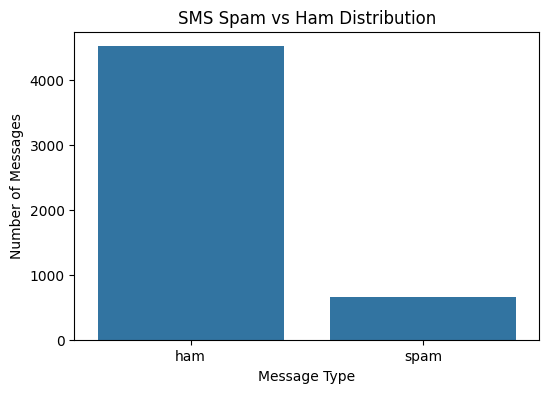

In [9]:
print(df['label'].value_counts())

plt.figure(figsize=(6,4))

sns.countplot(data=df, x='label')

plt.title("SMS Spam vs Ham Distribution")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")

plt.show()

In [10]:
df['label_num'] = df['label'].map({
    'ham': 0,
    'spam': 1
})

print(df.head())

  label                                            message  label_num
0   ham  Go until jurong point, crazy.. Available only ...          0
1   ham                      Ok lar... Joking wif u oni...          0
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...          1
3   ham  U dun say so early hor... U c already then say...          0
4   ham  Nah I don't think he goes to usf, he lives aro...          0


In [11]:
X = df['message']
y = df['label_num']

print("Input:")
print(X.head())

print("\nOutput:")
print(y.head())

Input:
0    Go until jurong point, crazy.. Available only ...
1                        Ok lar... Joking wif u oni...
2    Free entry in 2 a wkly comp to win FA Cup fina...
3    U dun say so early hor... U c already then say...
4    Nah I don't think he goes to usf, he lives aro...
Name: message, dtype: object

Output:
0    0
1    0
2    1
3    0
4    0
Name: label_num, dtype: int64


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

Training Samples: 4135
Testing Samples: 1034


In [13]:
tfidf = TfidfVectorizer(
    stop_words='english',
    lowercase=True
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF completed successfully!")
print("Training Shape:", X_train_tfidf.shape)
print("Testing Shape:", X_test_tfidf.shape)

TF-IDF completed successfully!
Training Shape: (4135, 7414)
Testing Shape: (1034, 7414)


In [14]:
model = MultinomialNB()

model.fit(X_train_tfidf, y_train)

print("Model trained successfully!")

Model trained successfully!


In [15]:
y_pred = model.predict(X_test_tfidf)

print("Actual Values:")
print(y_test.values[:10])

print("\nPredicted Values:")
print(y_pred[:10])

Actual Values:
[0 0 0 0 0 0 0 0 0 0]

Predicted Values:
[0 0 0 0 0 0 0 0 0 0]


In [16]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy * 100, "%")
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Ham', 'Spam']
))

Accuracy: 96.71179883945842 %
Precision: 1.0
Recall: 0.7404580152671756
F1 Score: 0.8508771929824561

Classification Report:
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       903
        Spam       1.00      0.74      0.85       131

    accuracy                           0.97      1034
   macro avg       0.98      0.87      0.92      1034
weighted avg       0.97      0.97      0.96      1034



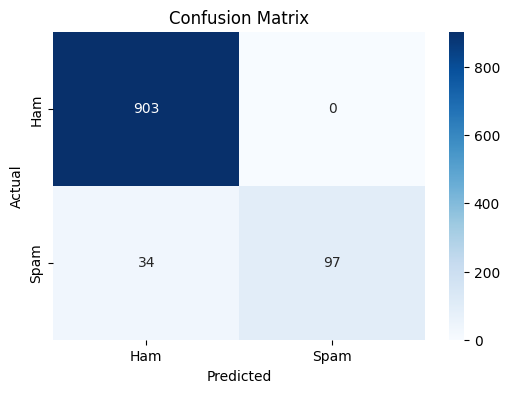

In [17]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

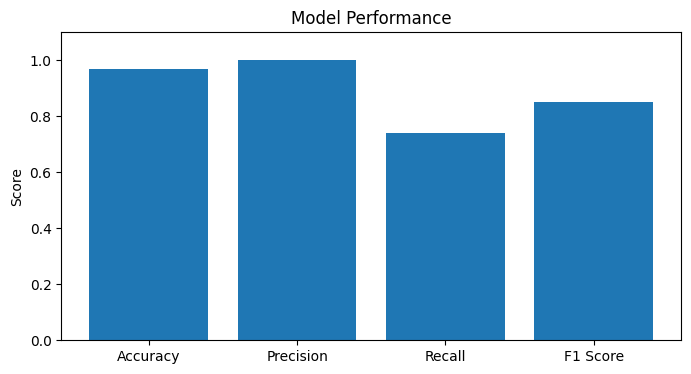

In [18]:
metrics = {
    'Accuracy': accuracy,
    'Precision': precision,
    'Recall': recall,
    'F1 Score': f1
}

plt.figure(figsize=(8,4))

plt.bar(metrics.keys(), metrics.values())

plt.title("Model Performance")
plt.ylabel("Score")
plt.ylim(0, 1.1)

plt.show()

In [19]:
def predict_sms(message):

    message_tfidf = tfidf.transform([message])

    prediction = model.predict(message_tfidf)[0]

    probability = model.predict_proba(message_tfidf)[0][1]

    print("\nMessage:", message)

    if prediction == 1:
        print("Prediction: SPAM")
    else:
        print("Prediction: HAM")

    print("Spam Probability:", round(probability * 100, 2), "%")

In [20]:
predict_sms("Congratulations! You won a free lottery prize. Claim now!")

predict_sms("Hey, are you coming to college tomorrow?")

predict_sms("URGENT! You have won a free mobile phone!")

predict_sms("Please bring your notebook to class tomorrow.")


Message: Congratulations! You won a free lottery prize. Claim now!
Prediction: SPAM
Spam Probability: 93.89 %

Message: Hey, are you coming to college tomorrow?
Prediction: HAM
Spam Probability: 0.47 %

Message: URGENT! You have won a free mobile phone!
Prediction: SPAM
Spam Probability: 71.29 %

Message: Please bring your notebook to class tomorrow.
Prediction: HAM
Spam Probability: 1.77 %


In [21]:
message = input("Enter your SMS message: ")

predict_sms(message)


Enter your SMS message: Congratulations! You have won a free iPhone. Claim your prize now!

Message: Congratulations! You have won a free iPhone. Claim your prize now!
Prediction: SPAM
Spam Probability: 86.8 %


In [22]:
results = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Score': [accuracy, precision, recall, f1]
})

print("FINAL MODEL RESULTS")
print(results)

FINAL MODEL RESULTS
      Metric     Score
0   Accuracy  0.967118
1  Precision  1.000000
2     Recall  0.740458
3   F1 Score  0.850877
